In [23]:
import cv2
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [15]:
# Open file dialog to select the spreadsheet file
spreadsheet_path = filedialog.askopenfilename(
    title="Select the Spreadsheet File",
    filetypes=[("Excel files", "*.xlsx")]
)
fused_data = pd.read_excel(spreadsheet_path)
# Display the first few rows of the dataframe to understand its structure
fused_data.head()

,FRAME,IMAGE TYPE,POLYP ID,SIZE,SHAPE,LOCATION,BOUNDING BOX,ORIGINAL DATASET
0,a20f8f487bd1479f93bf3ffda32b4708.png,WL,piba-0001,5.0,Is,ASCENDING_COLON,"162,194,315,355",piba
1,d74d154548a64c56abfed6467de54ba7.png,NBI,piba-0002,6.0,Ip,SIGMOID,"255,317,458,464",piba
2,d0ec641045f04c78bf4ad06fca5c2e63.png,NBI,piba-0003,2.0,IIa,SIGMOID,"81,242,374,457",piba
3,77711dd11d58447782da5f29c879f6db.png,WL,piba-0004,3.0,IIa,RECTUM,"108,249,227,342",piba
4,2d0ae381800741ba84d78d132079670a.png,NBI,piba-0005,15.0,Ip,SIGMOID,"301,43,565,429",piba


In [16]:
fused_data['IMAGE TYPE'].value_counts()

IMAGE TYPE
WL     73712
NBI    10780
Name: count, dtype: int64

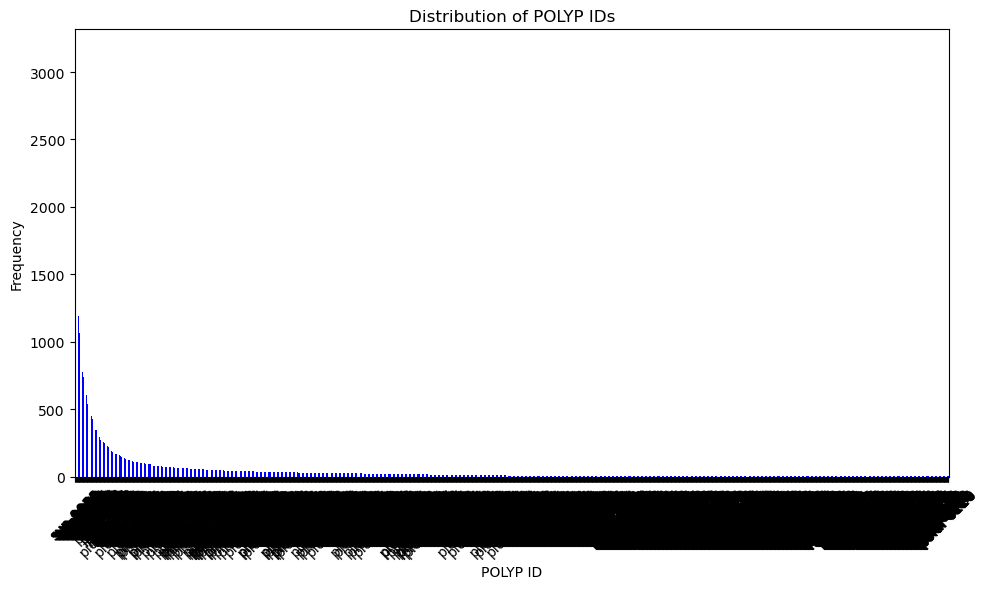

In [17]:
polyp_id_distribution = fused_data['POLYP ID'].value_counts()

# Plot the histogram
plt.figure(figsize=(10, 6))  # Set the size of the plot
polyp_id_distribution.plot(kind='bar', color='blue')  # Use a bar chart for the histogram
plt.title('Distribution of POLYP IDs')
plt.xlabel('POLYP ID')
plt.ylabel('Frequency')
plt.xticks(rotation=45)  # Rotate the x labels to make them more readable
plt.tight_layout()  # Adjust subplots to give some more room
plt.show()


In [18]:
fused_data['SHAPE'].value_counts()

SHAPE
Is     40169
IIa    25941
Ip     12707
Isp     4458
IIb     1120
III       59
IIc       38
Name: count, dtype: int64

In [19]:
fused_data['POLYP ID'].value_counts()

POLYP ID
sun-0020      3159
sun-0051      1737
sun-0066      1685
sun-0085      1393
sun-0068      1319
              ... 
polar-0227       1
polar-0228       1
polar-0229       1
polar-0230       1
polar-0720       1
Name: count, Length: 1959, dtype: int64

In [21]:
# Group by 'POLYP ID' and aggregate 'SHAPE' values into a list
shape_list_per_polyp_id = fused_data.groupby('POLYP ID')['SHAPE'].agg(lambda x: list(set(x)))

# Display the result
print(shape_list_per_polyp_id)

POLYP ID
piba-0001     [Is]
piba-0002     [Ip]
piba-0003    [IIa]
piba-0004    [IIa]
piba-0005     [Ip]
             ...  
sun-0096      [Is]
sun-0097     [IIa]
sun-0098     [IIa]
sun-0099      [Is]
sun-0100     [IIa]
Name: SHAPE, Length: 1959, dtype: object


In [29]:
# Group by 'SHAPE' and count unique 'POLYP ID'
polyps_per_shape = fused_data.groupby('SHAPE')['POLYP ID'].nunique()
print(polyps_per_shape)

SHAPE
III       3
IIa     390
IIb      60
IIc       8
Ip      343
Is     1139
Isp      16
Name: POLYP ID, dtype: int64


In [22]:
# Group by 'POLYP ID' and count the unique 'SHAPE' values for each
shape_uniqueness_per_polyp_id = fused_data.groupby('POLYP ID')['SHAPE'].nunique()

# Check for any POLYP ID with more than one SHAPE type
multiple_shapes = shape_uniqueness_per_polyp_id[shape_uniqueness_per_polyp_id > 1]

# Display the results
if multiple_shapes.empty:
    print("Every POLYP ID is associated with exactly one SHAPE type.")
else:
    print("Some POLYP IDs are associated with more than one SHAPE type:")
    print(multiple_shapes)

Every POLYP ID is associated with exactly one SHAPE type.


In [27]:
# Extract unique POLYP ID with their SHAPE
unique_polyps = fused_data[['POLYP ID', 'SHAPE']].drop_duplicates()

# Calculate split sizes
train_size = 0.7
# Adjusting test_size to split the remaining data into validation and test equally
test_size = 0.8

# First split: separate training set from temp set (which will be split into validation and test)
train_polyps, temp_polyps = train_test_split(unique_polyps, test_size=1-train_size, stratify=unique_polyps['SHAPE'], random_state=42)

# Second split: split the temp set into validation and test sets
val_polyps, test_polyps = train_test_split(temp_polyps, test_size=test_size, stratify=temp_polyps['SHAPE'], random_state=42)

# Select records in the original dataframe based on the training, validation, and testing POLYP IDs
train_df = fused_data[fused_data['POLYP ID'].isin(train_polyps['POLYP ID'])]
val_df = fused_data[fused_data['POLYP ID'].isin(val_polyps['POLYP ID'])]
test_df = fused_data[fused_data['POLYP ID'].isin(test_polyps['POLYP ID'])]

print("Training, validation, and testing datasets created, stratified by SHAPE.")


ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:
shape_counts_per_polyp_id = fused_data.groupby(['POLYP ID', 'SHAPE']).size().reset_index(name='Count')

print(shape_counts_per_polyp_id)

# Plot the histogram
shape_counts_per_polyp_id.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Count of Each SHAPE for Each POLYP ID')
plt.xlabel('POLYP ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='SHAPE')
plt.tight_layout()
plt.show()

In [ ]:
# Group by 'POLYP ID' and 'SHAPE' and count the entries, unstacking the 'SHAPE'
shape_counts_per_polyp_id = fused_data.groupby(['POLYP ID', 'SHAPE']).size().unstack(fill_value=0)

# Find where the count is zero
zero_counts = shape_counts_per_polyp_id[shape_counts_per_polyp_id == 0].stack()

# Calculate the total number of possible combinations
total_combinations = shape_counts_per_polyp_id.shape[0] * shape_counts_per_polyp_id.shape[1]

# Count zero occurrences
zero_count = zero_counts.size

# Calculate the percentage of zero count combinations
zero_percent = (zero_count / total_combinations) * 100

# Display the results
print(f"Total combinations: {total_combinations}")
print(f"Zero count combinations: {zero_count}")
print(f"Percentage of zero count combinations: {zero_percent:.2f}%")


In [ ]:
# Group by ColumnA and ColumnB, then count the rows for each group
result = fused_data.groupby(['IMAGE TYPE', 'SHAPE']).size().reset_index(name='Count')

# Display the result
print(result)

In [ ]:
fused_data['ORIGINAL DATASET'].value_counts()

In [ ]:
fused_data['SIZE'].value_counts()